## Этап 1. Загрузка и подготовка данных 
Загрузите данные из файла. Выполните первичный анализ структуры: определите, сколько записей содержит датасет, какие колонки присутствуют, какие типы данных в них хранятся. Обратите внимание, что данные представлены в широком формате, где каждый год — отдельная колонка, а каждая строка соответствует одному региону. Преобразуйте данные из широкого формата в длинный: одна строка должна соответствовать сочетанию «регион — год», а значение показателя должно находиться в отдельной колонке. После преобразования сформируйте отдельный временной ряд для каждого региона, где индексом является год, а значениями — соответствующие показатели потребления. 
В файле есть пропуски: часть из них обозначена пустыми ячейками, часть — символом «…». Из-за этого числовые столбцы при загрузке могут считываться как текстовые. Приведите годовые показатели к числовому формату, заменив специальные обозначения на пропуски. У разных территорий разная глубина исторических данных: у Крыма и Севастополя отсутствуют значения за 14 лет, у некоторых агрегированных записей — за 11 лет. Для основного анализа используйте только территории с полным рядом данных за весь доступный период (2000–2023 годы). Не восстанавливайте длительные начальные фрагменты ряда интерполяцией или экстраполяцией. В отчёте перечислите исключённые территории и объясните причины их исключения.

In [ ]:
from pathlib import Path
import pandas as pd
from numpy import isin
import seaborn as sns
import numpy as np

import pandas as pd
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.metrics import silhouette_samples
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MultiLabelBinarizer,RobustScaler
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import RobustScaler
from scipy.cluster.hierarchy import dendrogram

In [143]:
datapath = Path('data')
datapath.mkdir(exist_ok=True)
file_name = 'rsdocs_1491005410458_wide_appendix_2025.csv'
df = pd.read_csv(datapath / file_name,
                encoding='utf-8',
                dtype=str,
                na_values=['…', ''])


Для кластеризации и прогнозирования используйте только субъекты Российской Федерации. Исключите из анализа строки, соответствующие Российской Федерации в целом, федеральным округам, а также дублирующиеся агрегированные записи (например, Тюменская область без автономных округов). Работу нужно выполнять с данными по конкретным регионам, а не по их агрегатам.

In [144]:
rows_to_drop = [
    'Фактическое конечное потребление домашних хозяйств на территории субъектов Российской Федерации – всего',
    'Архангельская область без автономного округа',
    'Тюменская область без автономных округов',
    'Республика Крым',
    'г. Севастополь'
]

df = df.loc[~df['region_name'].isin(rows_to_drop)]
df = df.loc[~df['region_name'].str.contains('федераль')]


In [145]:
df['region_name'].unique().tolist()

['Белгородская область',
 'Брянская область',
 'Владимирская область',
 'Воронежская область',
 'Ивановская область',
 'Калужская область',
 'Костромская область',
 'Курская область',
 'Липецкая область',
 'Московская область',
 'Орловская область',
 'Рязанская область',
 'Смоленская область',
 'Тамбовская область',
 'Тверская область',
 'Тульская область',
 'Ярославская область',
 'г. Москва',
 'Республика Карелия',
 'Республика Коми',
 'Архангельская область',
 'Ненецкий автономный округ',
 'Вологодская область',
 'Калинингpадская область',
 'Ленинградская область',
 'Мурманская область',
 'Новгородская область',
 'Псковская область',
 'г. Санкт-Петербург',
 'Республика Адыгея',
 'Республика Калмыкия',
 'Краснодарский край',
 'Астраханская область',
 'Волгоградская область',
 'Ростовская область',
 'Республика Дагестан',
 'Республика Ингушетия',
 'Кабардино-Балкарская Республика',
 'Карачаево-Черкесская Республика',
 'Республика Северная Осетия – Алания',
 'Чеченская Республика',
 'С

In [146]:
df_long = pd.melt(
    df,
    id_vars= ['region_name', 'region_code', 'indicator_name', 'measure_unit'],  # колонки, которые нужно сохранить
    value_vars=None,  # колонки для разворота (по умолчанию — все остальные)
    var_name='year',  # имя для новой колонки с названиями (по умолчанию 'variable')
    value_name="value",  # имя для новой колонки со значениями (по умолчанию 'value')
    ignore_index=True,  # сбрасывать ли индекс (по умолчанию True)
)
df_long = df_long.dropna()
df_long = df_long[['region_name', 'year','value']]
df_long['value'] = df_long['value'].str.replace(',','.').astype(float)
df_long = df_long.sort_values(['region_name','year']).reset_index(drop=True)
df_long['year'] = df_long['year'].astype(int)

## Этап 2. Кластерный анализ регионов 
Чтобы сгруппировать регионы по схожести динамики показателя, вам потребуется выполнить кластеризацию. Вы можете использовать K-means или любой другой алгоритм кластеризации, с которым вы знакомы по курсу машинного обучения (например, агломеративную иерархическую кластеризацию). Выбор конкретного метода остаётся за вами; в отчёте нужно обосновать, почему вы выбрали именно этот алгоритм. В описании этапа ниже приведены рекомендации для K-means, но вы можете адаптировать их под выбранный метод.
На основе агрегированных характеристик временных рядов разделите все регионы на несколько групп. Для этого для каждого региона извлеките признаки, характеризующие его временной ряд. Учтите, что данные представлены в текущих ценах, поэтому абсолютные показатели (среднее значение, стандартное отклонение) в значительной степени отражают масштаб экономики региона и общий рост цен, а не специфику его динамики. Чтобы кластеризация выделяла регионы со сходными траекториями развития, а не просто регионы со сходным уровнем потребления, используйте набор признаков, включающий как минимум один относительный показатель динамики.
Рекомендуемый набор признаков для каждого региона (выберите не менее четырёх):
    • среднее значение за период (отражает общий уровень потребления в регионе);
    • коэффициент вариации (стандартное отклонение, делённое на среднее — характеризует относительную волатильность ряда, не зависящую от масштаба);
    • средний годовой темп роста (или медианный темп роста);
    • относительное изменение за весь период (значение в последнем году относительно первого);
    • максимальное годовое падение (наибольшее отрицательное изменение за один год);
    • доля лет с отрицательной динамикой (число лет, когда показатель снизился относительно предыдущего года).
Этот набор позволит выделить регионы не только по уровню потребления, но и по характеру его изменения: где рост устойчив, где он сменяется падением, где динамика более волатильна, где более стабильна. 
После извлечения признаков выполните их стандартизацию, затем проведите кластеризацию. Рассмотрите варианты от двух до четырёх кластеров. Для каждого варианта рассчитайте silhouette score и оцените содержательную интерпретируемость полученных групп. Выберите оптимальное число кластеров на основе совокупности этих двух критериев — числовой метрики и экономического смысла. Силуэт сам по себе не является достаточным основанием для выбора, если полученные группы трудно интерпретировать. В отчёте обоснуйте свой выбор: приведите значения silhouette score для каждого варианта и объясните, почему выбранное число кластеров лучше других с точки зрения содержательной интерпретации.
Для каждого кластера дайте содержательное описание: какие регионы в него попали, каков средний уровень потребления, какие особенности динамики характерны для этой группы.

In [147]:
# Рассчитываем показатели для каждого региона


def region_stats_make(df_long):
    # Создаем временной ряд для каждого региона
    time_series = df_long.pivot(
    index='year',  # устанавливаем год как индекс
    columns='region_name',  # регионы как столбцы
    values='value'  # значения показателя
)
    # Рассчитываем показатели для каждого региона
    region_stats = []
    for region in time_series.columns:
        series = time_series[region].dropna()

        # Среднее значение
        mean_value = series.mean()

        # Коэффициент вариации
        variation_coef = series.std() / mean_value

        # Среднегодовой прирост (CAGR): степень обратна числу лет между наблюдениями.
        years = series.index[-1] - series.index[0]
        growth_rate = (series.iloc[-1] / series.iloc[0]) ** (1 / years) - 1

        # Относительное изменение
        relative_change = series.iloc[-1] / series.iloc[0]

        # Максимальное падение
        yearly_changes = series.pct_change()
        max_drop = yearly_changes.min()

        # Доля лет с отрицательной динамикой
        negative_years = (yearly_changes < 0).sum() / len(yearly_changes)

        region_stats.append({
            'region_name': region,
            'Среднее значение': mean_value,
            'Коэфф. вариации': variation_coef,
            'Среднегодовой темп роста': growth_rate,
            'Относит. изменение': relative_change,
            'Макс. падение': max_drop,
            'Доля отрицат. динамики': negative_years
        })
    region_stats = pd.DataFrame(region_stats)
    # Форматируем результаты
    region_stats['Коэфф. вариации'] = region_stats['Коэфф. вариации'] * 100
    region_stats['Среднегодовой темп роста'] = region_stats['Среднегодовой темп роста'] * 100
    region_stats['Макс. падение'] = region_stats['Макс. падение'] * 100

    return region_stats

# Выводим результаты
region_stats = region_stats_make(df_long)
region_stats

,region_name,Среднее значение,Коэфф. вариации,Среднегодовой темп роста,Относит. изменение,Макс. падение,Доля отрицат. динамики
0,Алтайский край,166038.220833,69.385702,15.311520,26.489394,-1.029618,0.041667
1,Амурская область,231900.291667,78.213754,15.874638,29.630089,3.508777,0.000000
2,Архангельская область,253850.283333,74.248898,16.106854,31.026354,3.716445,0.000000
3,Астраханская область,180520.654167,66.050339,14.702069,23.449782,0.861605,0.000000
4,Белгородская область,204367.341667,77.000531,15.314152,26.503303,5.376965,0.000000
...,...,...,...,...,...,...,...
77,Чукотский автономный округ,369809.887500,67.666672,15.669343,28.445933,-3.611779,0.041667
78,Ямало-Ненецкий автономный округ,436201.652381,47.284623,11.253623,8.438850,-5.512711,0.047619
79,Ярославская область,199438.087500,74.676741,15.867348,29.587246,4.444213,0.000000
80,г. Москва,504230.937500,58.183507,11.316467,11.772441,0.281215,0.000000


Размерность (82, 6)


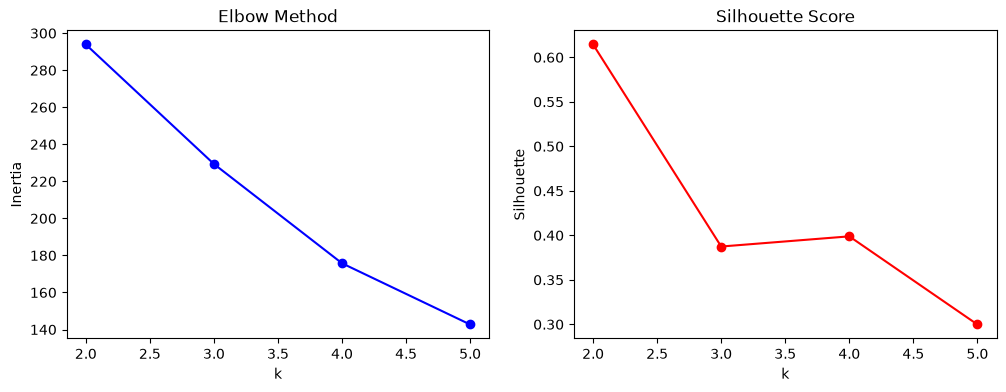

In [148]:

X = region_stats[region_stats.columns[~region_stats.columns.isin(['region_name'])]]



print(f'Размерность {X .shape}')

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
pca = PCA(n_components=0.90, random_state=1)
X_pca = pca.fit_transform(X_scaled)

k_range = range(2,6,1)
kmean_score = []
inertias = []
sil_scores = []
for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=1)
    labels = km.fit_predict(X_pca)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_pca, labels))

    model_score_dict = {'model':'KMeans','k':k,'inertia':round(km.inertia_,2),'silhouette':sil_scores}
    kmean_score.append(model_score_dict)

# Графики
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12,4))
ax1.plot(k_range, inertias, 'bo-')
ax1.set_xlabel('k')
ax1.set_ylabel('Inertia')
ax1.set_title('Elbow Method')

ax2.plot(k_range, sil_scores, 'ro-')
ax2.set_xlabel('k')
ax2.set_ylabel('Silhouette')
ax2.set_title('Silhouette Score')

plt.show()



Размерность (82, 6)

Metrics for AgglomerativeClustering (n_clusters=2):
silhouette_score: 0.6317
calinski_harabasz_score: 37.9956
davies_bouldin_score: 0.8979
----------------------------------------

Metrics for AgglomerativeClustering (n_clusters=3):
silhouette_score: 0.2724
calinski_harabasz_score: 32.4449
davies_bouldin_score: 1.3960
----------------------------------------

Metrics for AgglomerativeClustering (n_clusters=4):
silhouette_score: 0.2804
calinski_harabasz_score: 33.6901
davies_bouldin_score: 1.0256
----------------------------------------

Metrics for AgglomerativeClustering (n_clusters=5):
silhouette_score: 0.3208
calinski_harabasz_score: 36.5592
davies_bouldin_score: 0.9476
----------------------------------------


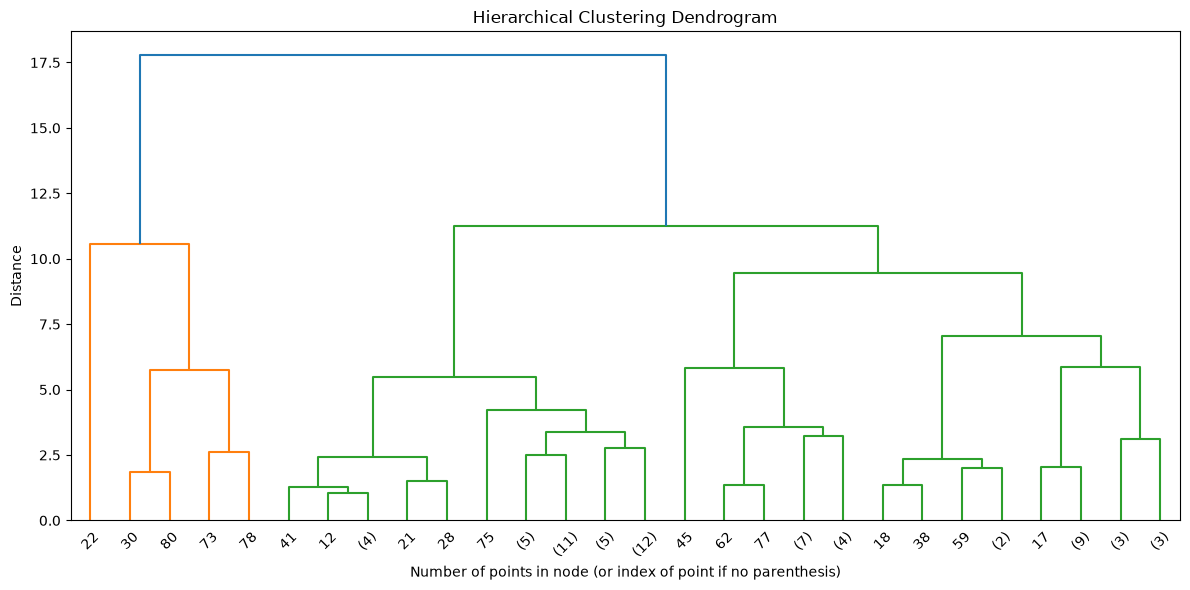


Анализ кластеров для k=2:

Кластер 0:
Регионы: Алтайский край, Амурская область, Архангельская область, Астраханская область, Белгородская область, Брянская область, Владимирская область, Волгоградская область, Вологодская область, Воронежская область, Еврейская автономная область, Забайкальский край, Ивановская область, Иркутская область, Кабардино-Балкарская Республика, Калужская область, Камчатский край, Карачаево-Черкесская Республика, Кемеровская область, Кировская область, Костромская область, Краснодарский край, Курганская область, Курская область, Ленинградская область, Липецкая область, Магаданская область, Московская область, Мурманская область, Нижегородская область, Новгородская область, Новосибирская область, Омская область, Оренбургская область, Орловская область, Пензенская область, Пермский край, Приморский край, Псковская область, Республика Адыгея, Республика Алтай, Республика Башкортостан, Республика Бурятия, Республика Дагестан, Республика Ингушетия, Республика Кал

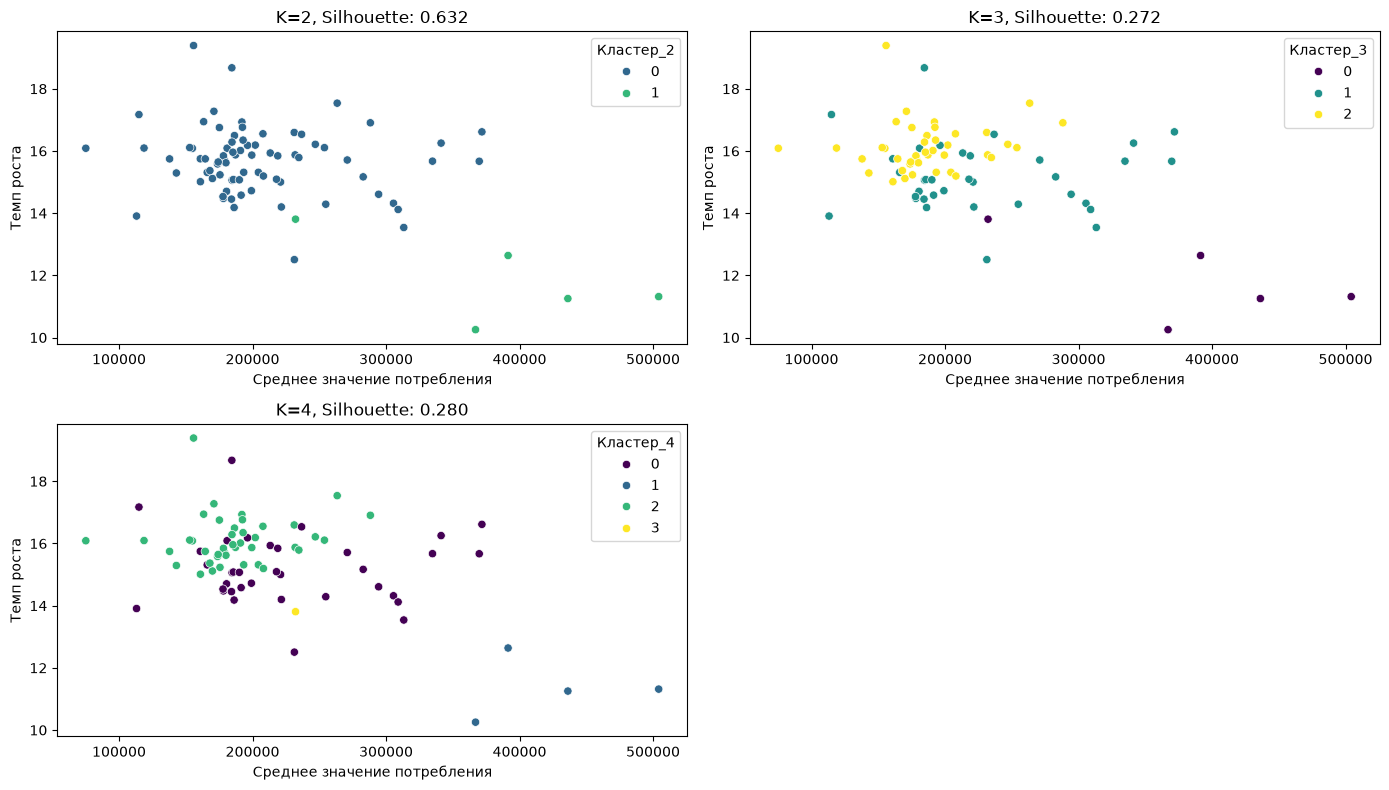

In [149]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from scipy.cluster.hierarchy import dendrogram




# Метки предыдущих запусков не должны попадать в признаки.
feature_columns = [
    'Среднее значение', 'Коэфф. вариации', 'Среднегодовой темп роста',
    'Относит. изменение', 'Макс. падение', 'Доля отрицат. динамики'
]
X = region_stats[feature_columns]



print(f'Размерность {X .shape}')

# Масштабирование
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Иерархическая кластеризация
# Попробуем разные количества кластеров
results = {}
for n_clusters in [2, 3, 4, 5]:
    model = AgglomerativeClustering(
        n_clusters=n_clusters,
        linkage='ward'  # ward минимизирует внутрикластерную дисперсию
    )
    y_pred = model.fit_predict(X_scaled)
    
    silhouette = silhouette_score(X_scaled, y_pred)
    calinski = calinski_harabasz_score(X_scaled, y_pred)
    davies = davies_bouldin_score(X_scaled, y_pred)

    region_stats[f'Кластер_{n_clusters}'] = y_pred
    results[n_clusters] = {
        'score': silhouette,
        'calinski': calinski,
        'davies': davies
    }
    
    print(f"\nMetrics for AgglomerativeClustering (n_clusters={n_clusters}):")
    print(f"silhouette_score: {silhouette:.4f}")
    print(f"calinski_harabasz_score: {calinski:.4f}")
    print(f"davies_bouldin_score: {davies:.4f}")
    print("-" * 40)

# Построение дендрограммы
# Используем последнюю модель для визуализации
model = AgglomerativeClustering(distance_threshold=0, n_clusters=None, linkage='ward')
model.fit(X_scaled)

# Создание матрицы связей для дендрограммы
def plot_dendrogram(model, **kwargs):
    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)
    for i, merge in enumerate(model.children_):
        current_count = 0
        for child_idx in merge:
            if child_idx < n_samples:
                current_count += 1
            else:
                current_count += counts[child_idx - n_samples]
        counts[i] = current_count
    
    linkage_matrix = np.column_stack([model.children_, model.distances_, counts]).astype(float)
    
    dendrogram(linkage_matrix, **kwargs)

plt.figure(figsize=(12, 6))
plot_dendrogram(model, truncate_mode='level', p=5)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Number of points in node (or index of point if no parenthesis)")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()

# Анализ результатов кластеризации
for k in range(2, 5):
    print(f'\nАнализ кластеров для k={k}:')
    for cluster in region_stats[f'Кластер_{k}'].unique():
        cluster_data = region_stats[region_stats[f'Кластер_{k}'] == cluster]
        print(f'\nКластер {cluster}:')
        print(f'Регионы: {", ".join(cluster_data["region_name"])}')
        print(f'Среднее значение показателей:')
        print(cluster_data[['Среднее значение',
                          'Коэфф. вариации',
                          'Среднегодовой темп роста']].mean())

# Визуализация кластеров
plt.figure(figsize=(14, 8))
for k in range(2, 5):
    plt.subplot(2, 2, k-1)
    sns.scatterplot(x='Среднее значение',
                   y='Среднегодовой темп роста',
                   hue=f'Кластер_{k}',
                   data=region_stats,
                   palette='viridis')
    plt.title(f'K={k}, Silhouette: {results[k]["score"]:.3f}')
    plt.xlabel('Среднее значение потребления')
    plt.ylabel('Темп роста')

plt.tight_layout()
plt.show()

In [150]:
region_stats

,region_name,Среднее значение,Коэфф. вариации,Среднегодовой темп роста,Относит. изменение,Макс. падение,Доля отрицат. динамики,Кластер_2,Кластер_3,Кластер_4,Кластер_5
0,Алтайский край,166038.220833,69.385702,15.311520,26.489394,-1.029618,0.041667,0,1,0,1
1,Амурская область,231900.291667,78.213754,15.874638,29.630089,3.508777,0.000000,0,2,2,2
2,Архангельская область,253850.283333,74.248898,16.106854,31.026354,3.716445,0.000000,0,2,2,2
3,Астраханская область,180520.654167,66.050339,14.702069,23.449782,0.861605,0.000000,0,1,0,0
4,Белгородская область,204367.341667,77.000531,15.314152,26.503303,5.376965,0.000000,0,2,2,2
...,...,...,...,...,...,...,...,...,...,...,...
77,Чукотский автономный округ,369809.887500,67.666672,15.669343,28.445933,-3.611779,0.041667,0,1,0,1
78,Ямало-Ненецкий автономный округ,436201.652381,47.284623,11.253623,8.438850,-5.512711,0.047619,1,0,1,4
79,Ярославская область,199438.087500,74.676741,15.867348,29.587246,4.444213,0.000000,0,2,2,2
80,г. Москва,504230.937500,58.183507,11.316467,11.772441,0.281215,0.000000,1,0,1,4


In [151]:
model = AgglomerativeClustering(n_clusters=3)
region_stats['cluster'] = model.fit_predict(X_scaled)

# Списки регионов в каждом кластере.
for cluster, group in region_stats.groupby('cluster', sort=True):
    print(f'Кластер {cluster} — регионов: {len(group)}')
    for region in sorted(group['region_name']):
        print(f'  • {region}')
    print()

# Медианы исходных характеристик, без столбцов с метками кластеров.
median_features = [
    'Среднее значение', 'Коэфф. вариации', 'Среднегодовой темп роста',
    'Относит. изменение', 'Макс. падение', 'Доля отрицат. динамики'
]
cluster_medians = region_stats.groupby('cluster')[median_features].median()
print('Медианные характеристики кластеров:')
display(cluster_medians.round(3))


Кластер 0 — регионов: 5
  • Красноярский край
  • Ненецкий автономный округ
  • Ханты-Мансийский автономный округ – Югра
  • Ямало-Ненецкий автономный округ
  • г. Москва

Кластер 1 — регионов: 35
  • Алтайский край
  • Астраханская область
  • Вологодская область
  • Воронежская область
  • Забайкальский край
  • Иркутская область
  • Камчатский край
  • Карачаево-Черкесская Республика
  • Кемеровская область
  • Курганская область
  • Магаданская область
  • Мурманская область
  • Новгородская область
  • Новосибирская область
  • Омская область
  • Пермский край
  • Приморский край
  • Республика Башкортостан
  • Республика Дагестан
  • Республика Калмыкия
  • Республика Коми
  • Республика Саха (Якутия)
  • Ростовская область
  • Самарская область
  • Сахалинская область
  • Свердловская область
  • Смоленская область
  • Ставропольский край
  • Тамбовская область
  • Томская область
  • Тюменская область
  • Хабаровский край
  • Челябинская область
  • Чукотский автономный округ
 

,Среднее значение,Коэфф. вариации,Среднегодовой темп роста,Относит. изменение,Макс. падение,Доля отрицат. динамики
cluster,,,,,,
0,391414.886,55.372,11.316,10.808,-5.513,0.042
1,213262.217,68.736,15.072,25.251,-0.310,0.042
2,182344.288,74.018,15.988,29.884,3.549,0.000


## Этап 3. Выбор регионов для детального прогнозирования 
На основе кластеризации, выполненной на предыдущем этапе, выберите три региона для построения прогнозов. Эти регионы должны представлять разные типы динамики, выявленные при кластеризации.
Если в результате кластеризации получилось три или менее кластеров, возьмите по одному региону из каждого кластера. Если кластеров больше трёх, выберите три региона из разных кластеров, которые наилучшим образом отражают разнообразие динамических паттернов.
Учитывайте при выборе:

    • регион должен быть репрезентативным для своего кластера (его показатели близки к средним по кластеру);
    • либо, наоборот, регион может представлять крайний, но содержательно интересный случай внутри кластера (например, самый высокий темп роста или максимальную волатильность).
    
Свой выбор обоснуйте в отчёте: почему выбран именно этот регион, чем он интересен и почему он репрезентирует свой кластер. Для каждого выбранного региона приведите базовую статистику: среднее значение, минимальное и максимальное значение за период, оценку тренда (коэффициент наклона линейной регрессии).
Этап 4. Анализ выбранных регионов 

In [177]:
features = [
    'Среднее значение',
    'Коэфф. вариации',
    'Среднегодовой темп роста',
    'Относит. изменение',
    'Макс. падение',
    'Доля отрицат. динамики'
]

scaled = pd.DataFrame(
    StandardScaler().fit_transform(region_stats[features]),
    index=region_stats.index,
    columns=features
)

regions_list = []

for cluster, group in region_stats.groupby('cluster', sort=True):
    cluster_features = scaled.loc[group.index]
    center = cluster_features.mean()

    # Квадрат евклидова расстояния до центра кластера.
    distances = cluster_features.sub(center).pow(2).sum(axis=1)
    chosen_idx = distances.idxmin()
    chosen = region_stats.loc[chosen_idx, 'region_name']

    regions_list.append(chosen)
    print(f'Для кластера {cluster} выбран регион: {chosen}')

Для кластера 0 выбран регион: Ямало-Ненецкий автономный округ
Для кластера 1 выбран регион: Ставропольский край
Для кластера 2 выбран регион: Курская область


Свой выбор обоснуйте в отчёте: почему выбран именно этот регион, чем он интересен и почему он репрезентирует свой кластер. Для каждого выбранного региона приведите базовую статистику: среднее значение, минимальное и максимальное значение за период, оценку тренда (коэффициент наклона линейной регрессии).

In [182]:
def selected_region_stats(df_long, regions_list):
    # Создаем временной ряд для каждого региона
    time_series = df_long.pivot(
    index='year',  # устанавливаем год как индекс
    columns='region_name',  # регионы как столбцы
    values='value'  # значения показателя
)
    # Рассчитываем показатели для каждого региона
    region_stats = []
    for region in regions_list:
        series = time_series[region].dropna()

        # Максимальное значение
        max_value = series.max()
        # Минимальное значение
        min_value = series.min()
        # среднее
        mean_value = series.mean()


        # Если индекс — годы, а value — значения
        x = series.index.astype(int)          # годы как числа
        y = series           # значения

        slope, intercept = np.polyfit(x, y, deg=1)



        region_stats.append({
            'region_name': region,
            'Максимальное значение': max_value,
            'Минимальное значение': min_value,
            'Среднее значение': mean_value,
            'Наклон': slope,
        })
    region_stats = pd.DataFrame(region_stats)


    return region_stats

selected_region_stats(df_long, regions_list)

,region_name,Максимальное значение,Минимальное значение,Среднее значение,Наклон
0,Ямало-Ненецкий автономный округ,851988.0,100960.2,436201.652381,32871.318701
1,Ставропольский край,440721.9,17488.3,184669.137500,17270.515609
2,Курская область,478025.8,15690.0,190928.508333,19575.576000


## Этап 4. Анализ выбранных регионов 
Для каждого из трёх выбранных регионов выполните полный анализ временного ряда. Постройте график исходного ряда. Оцените наличие тренда и циклических колебаний. Для выделения тренда используйте скользящее среднее или метод Ходрика — Прескотта (если сочтёте нужным). Проверьте каждый ряд на стационарность с помощью теста Дики — Фуллера и интерпретируйте результаты.
Поскольку данные годовые, внутригодовая сезонность отсутствует; сезонная декомпозиция к таким данным неприменима. В отчёте поясните, почему выделение сезонной компоненты для годовых данных не имеет смысла.
Постройте графики автокорреляционной функции (ACF) и частной автокорреляционной функции (PACF) для каждого ряда. Проанализируйте полученные графики: на основе их вида сформулируйте предположения о возможных порядках авторегрессионной (p) и скользящей средней (q) компонент для модели ARIMA. Зафиксируйте свои гипотезы в отчёте: в дальнейшем вы сможете сравнить их с результатами автоматического подбора параметров.
Сравните регионы между собой: у какого из них более выражен тренд, у какого выше волатильность, какой из них стационарен, а какой нет, как отличаются их ACF и PACF. Все выводы должны опираться на полученные графики и числовые значения.


Анализ региона: Ямало-Ненецкий автономный округ


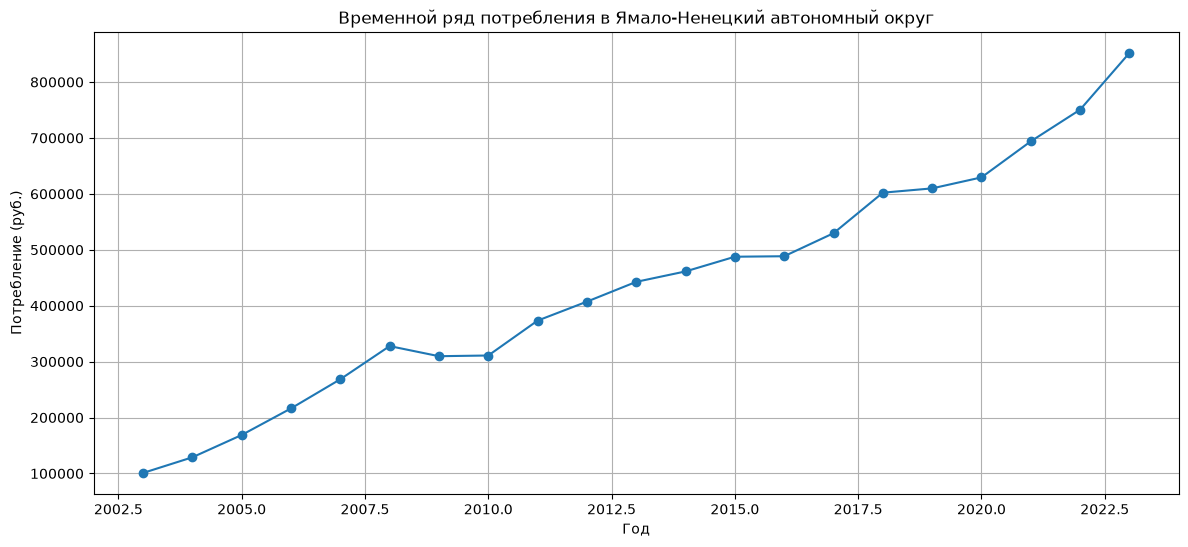

Статистика теста Дики-Фуллера: 3.1104809500185393
p-значение: 1.0
Вывод: p-value >= 0.05. Нулевую гипотезу отвергнуть не удалось.
Ряд НЕСТАЦИОНАРЕН (присутствует единичный корень).


/tmp/ipykernel_16231/3495127151.py:34: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(time_series[region].dropna())


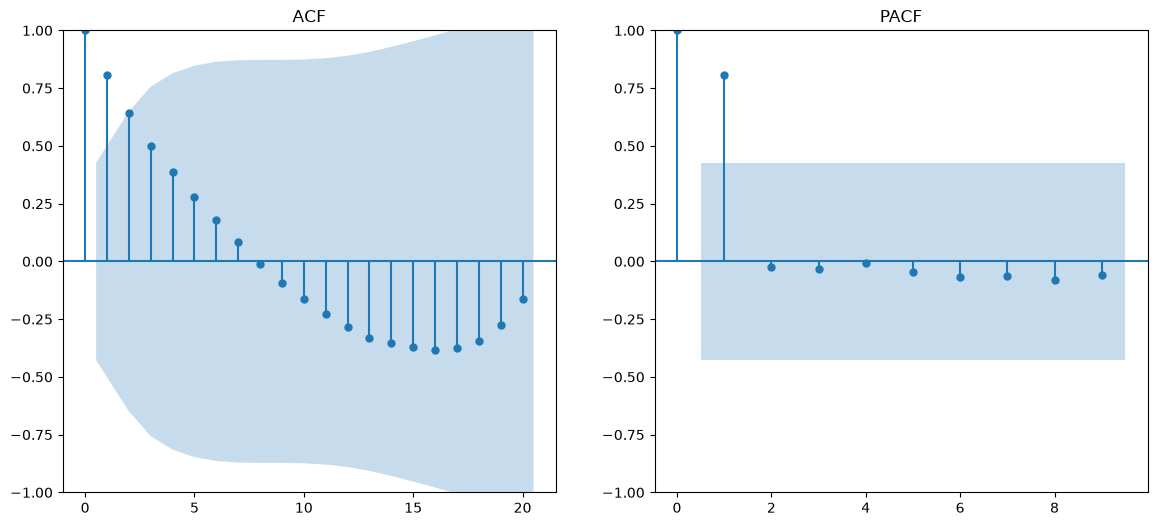

Среднее значение: 436,201.65
Стандартное отклонение: 206,256.31
Прирост за 2003–2023 гг.: 743.89%
Среднегодовой прирост (CAGR): 11.25%



Анализ региона: Ставропольский край


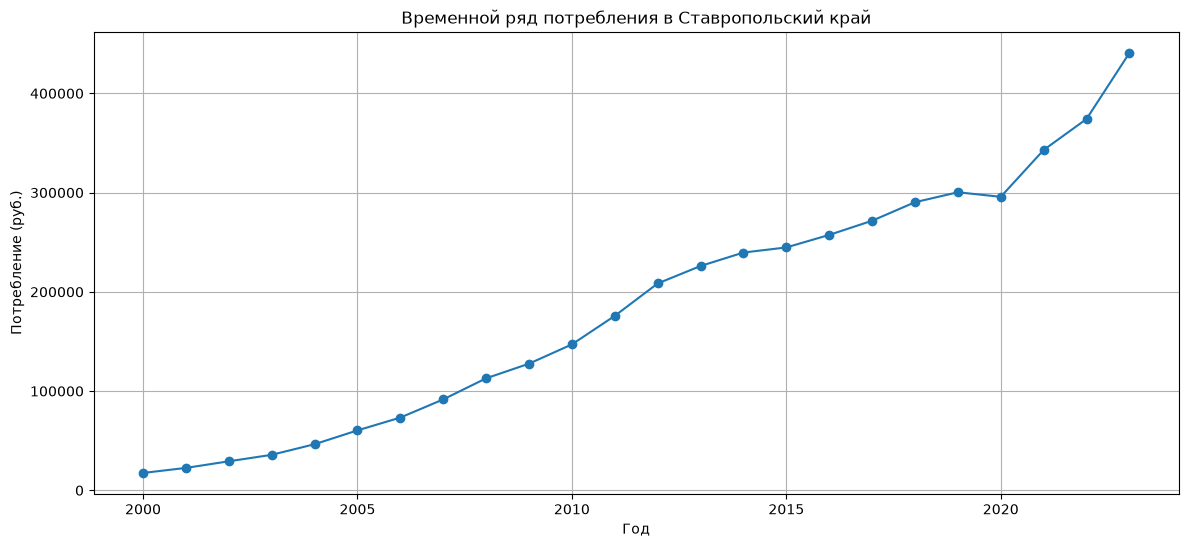

Статистика теста Дики-Фуллера: -0.765862203904777
p-значение: 0.8289447362964706
Вывод: p-value >= 0.05. Нулевую гипотезу отвергнуть не удалось.
Ряд НЕСТАЦИОНАРЕН (присутствует единичный корень).


/tmp/ipykernel_16231/3495127151.py:34: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(time_series[region].dropna())


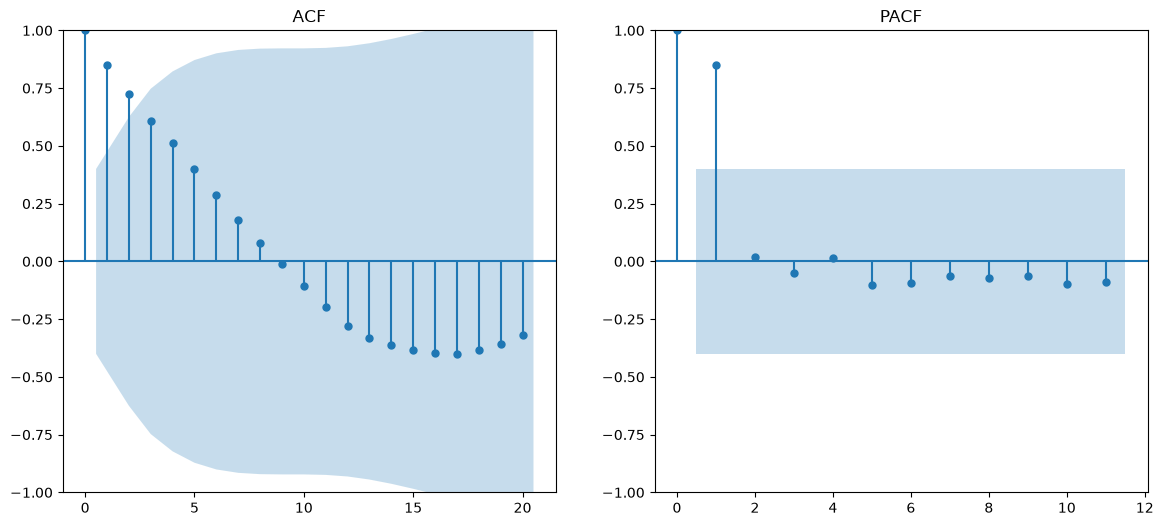

Среднее значение: 184,669.14
Стандартное отклонение: 123,577.04
Прирост за 2000–2023 гг.: 2420.10%
Среднегодовой прирост (CAGR): 15.06%



Анализ региона: Курская область


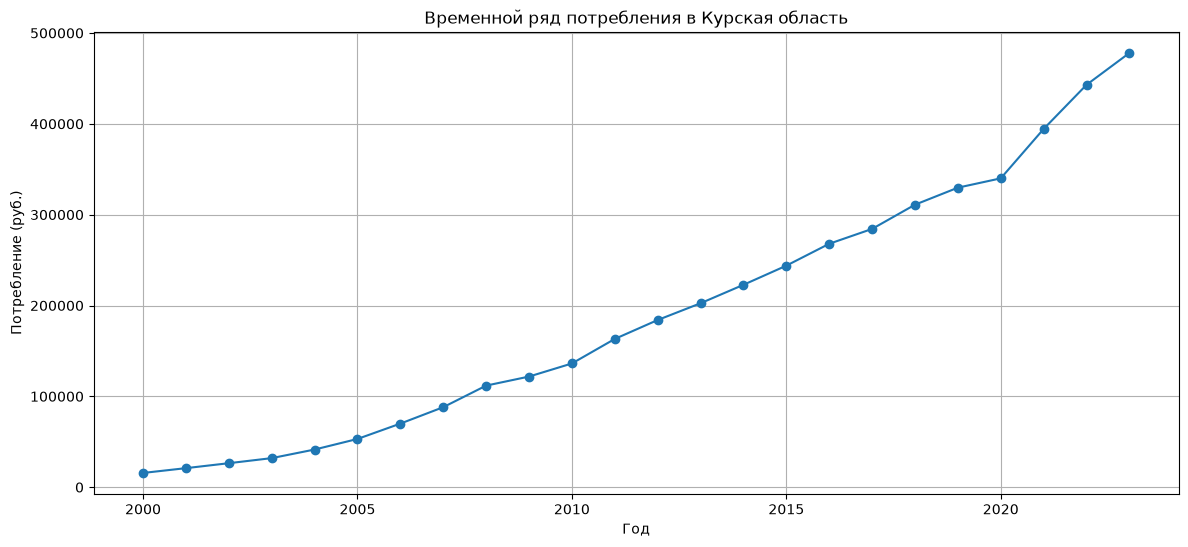

Статистика теста Дики-Фуллера: 4.627446993166929
p-значение: 1.0
Вывод: p-value >= 0.05. Нулевую гипотезу отвергнуть не удалось.
Ряд НЕСТАЦИОНАРЕН (присутствует единичный корень).


/tmp/ipykernel_16231/3495127151.py:34: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(time_series[region].dropna())


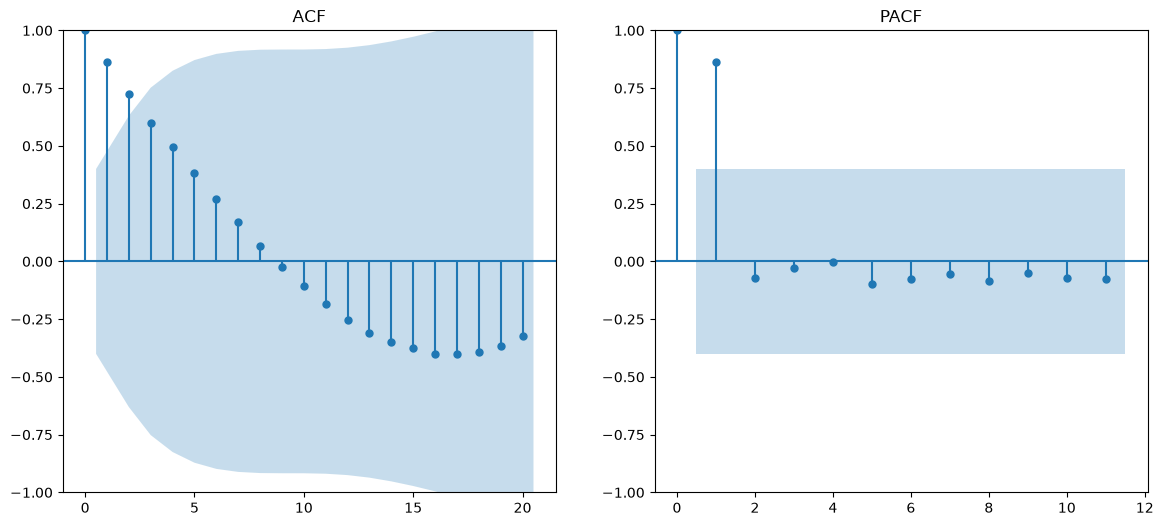

Среднее значение: 190,928.51
Стандартное отклонение: 140,670.71
Прирост за 2000–2023 гг.: 2946.69%
Среднегодовой прирост (CAGR): 16.02%




In [185]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf


# Выбираем три региона
regions = regions_list
data = df[df['region_name'].isin(regions)]

# Создаем отдельные временные ряды
time_series = df_long.pivot(
    index='year', columns='region_name', values='value'
).sort_index()

# Анализ каждого региона
for region in regions:
    print(f"\nАнализ региона: {region}")

    # Исходный ряд
    plt.figure(figsize=(14, 6))
    plt.plot(time_series[region], marker='o')
    plt.title(f'Временной ряд потребления в {region}')
    plt.xlabel('Год')
    plt.ylabel('Потребление (руб.)')
    plt.grid(True)
    plt.show()

    # Скользящее среднее для выявления тренда
    time_series[region + '_ma'] = time_series[region].rolling(window=3).mean()

    # Тест Дики-Фуллера на стационарность
    result = adfuller(time_series[region].dropna())
    print(f"Статистика теста Дики-Фуллера: {result[0]}")
    print(f"p-значение: {result[1]}")

    # 4. Автоматическая интерпретация
    alpha = 0.05
    if result[1] < alpha:
        print(f"Вывод: p-value < {alpha}. Нулевая гипотеза отвергается.")
        print("Ряд СТАЦИОНАРЕН (нет единичного корня).")
    else:
        print(f"Вывод: p-value >= {alpha}. Нулевую гипотезу отвергнуть не удалось.")
        print("Ряд НЕСТАЦИОНАРЕН (присутствует единичный корень).")

    # ACF требует лаг < n; для PACF используем лаг < n // 2.
    series = time_series[region].dropna()
    acf_lags = min(20, len(series) - 1)
    pacf_lags = min(20, len(series) // 2 - 1)

    plt.figure(figsize=(14, 6))
    plt.subplot(121)
    plot_acf(series, ax=plt.gca(), lags=acf_lags)
    plt.title('ACF')

    plt.subplot(122)
    plot_pacf(series, ax=plt.gca(), lags=pacf_lags)
    plt.title('PACF')
    plt.show()

    # Выводы
    print(f"Среднее значение: {time_series[region].mean():,.2f}")
    print(f"Стандартное отклонение: {time_series[region].std():,.2f}")
    total_growth = (series.iloc[-1] / series.iloc[0] - 1) * 100
    years = series.index[-1] - series.index[0]
    annual_growth = ((series.iloc[-1] / series.iloc[0]) ** (1 / years) - 1) * 100
    print(f"Прирост за {series.index[0]}–{series.index[-1]} гг.: {total_growth:.2f}%")
    print(f"Среднегодовой прирост (CAGR): {annual_growth:.2f}%")
    print("\n")
